## I. Làm sạch dữ liệu

## 1.Import thư viện và đọc file data 

In [1]:
# Dataset: Metro Interstate Traffic Volume (2012-2018).
# Bien nghien cuu: traffic_volume, so phuong tien trong mot gio.

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
OUT = ROOT / "outputs"
OUT_01 = OUT /"01_EDA_and_Probability_Distributions"
TABLE_DIR = OUT /"tables"
FIG = OUT /"01_EDA_and_Probability_Distributions"/ "figures"

#tao thu muc chua ton tai
OUT.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

DATA_PATH = Path(DATA/ "Metro_Interstate_Traffic_Volume.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Khong tim thay Metro_Interstate_Traffic_Volume.csv. "
        "Hay dat file CSV cung thu muc notebook."
    )

raw = pd.read_csv(DATA_PATH, keep_default_na=False)


## 3. Khám phá cấu trúc dữ liệu ban đầu
Nhóm xem các dòng đầu, dòng cuối, kích thước và kiểu dữ liệu của bộ dữ liệu để nắm được cấu trúc tổng quan trước khi xử lý.

In [2]:
# 1.2. Kiem tra cau truc va chat luong du lieu ban dau

# Xem 5 dòng đầu
display(raw.head())

# Xem 5 dòng cuối
display(raw.tail())

# Xem kích thước
print("Số bản ghi:", raw.shape[0])
print("Số biến:", raw.shape[1])

print("Kieu du lieu:")
print(raw.dtypes)

#kiem tra kieu du lieu
raw.info()


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,None,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,None,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,None,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,None,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,None,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
48199,None,283.45,0.0,0.0,75,Clouds,broken clouds,2018-09-30 19:00:00,3543
48200,None,282.76,0.0,0.0,90,Clouds,overcast clouds,2018-09-30 20:00:00,2781
48201,None,282.73,0.0,0.0,90,Thunderstorm,proximity thunderstorm,2018-09-30 21:00:00,2159
48202,None,282.09,0.0,0.0,90,Clouds,overcast clouds,2018-09-30 22:00:00,1450
48203,None,282.12,0.0,0.0,90,Clouds,overcast clouds,2018-09-30 23:00:00,954


Số bản ghi: 48204
Số biến: 9
Kieu du lieu:
holiday                    str
temp                   float64
rain_1h                float64
snow_1h                float64
clouds_all               int64
weather_main               str
weather_description        str
date_time                  str
traffic_volume           int64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              48204 non-null  str    
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  str    
 6   weather_description  48204 non-null  str    
 7   date_time            48204 non-null  str    
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3

## 3.1 Thống kê thông tin các biến

Bảng thống kê thể hiện kiểu dữ liệu, số lượng giá trị thiếu, tỷ lệ thiếu và số giá trị khác nhau của từng cột.

In [3]:
#bang kiem tra kieu du lieu va gia tri thieu
profile = pd.DataFrame({
    "Kieu_du_lieu": raw.dtypes.astype(str),
    "So_gia_tri_thieu": raw.isna().sum(),
    "Ty_le_thieu_%": (
        raw.isna().mean() * 100
    ).round(3),
    "So_gia_tri_khac_nhau": raw.nunique(dropna=True)
})

display(profile)

profile.to_csv(
    TABLE_DIR / "01_data_profile_original.csv",
    encoding="utf-8-sig"
)

,Kieu_du_lieu,So_gia_tri_thieu,Ty_le_thieu_%,So_gia_tri_khac_nhau
holiday,str,0,0.0,12
temp,float64,0,0.0,5843
rain_1h,float64,0,0.0,372
snow_1h,float64,0,0.0,12
clouds_all,int64,0,0.0,60
weather_main,str,0,0.0,11
weather_description,str,0,0.0,38
date_time,str,0,0.0,40575
traffic_volume,int64,0,0.0,6704


## 4. Kiểm tra dữ liệu thiếu và dòng trùng
Nhóm thống kê các dòng trùng hoàn toàn và giá trị thiếu trong từng cột để đánh giá chất lượng dữ liệu ban đầu.

In [4]:
print("Số dòng trùng hoàn toàn:", raw.duplicated().sum())

missing_table = pd.DataFrame({
    "So_gia_tri_thieu": raw.isna().sum(),
    "Ty_le_thieu_%": (
        raw.isna().mean() * 100
    ).round(3)
})

display(missing_table)

missing_table.to_csv(
    TABLE_DIR / "02_missing_values_original.csv",
    encoding="utf-8-sig"
)

Số dòng trùng hoàn toàn: 17


,So_gia_tri_thieu,Ty_le_thieu_%
holiday,0,0.0
temp,0,0.0
rain_1h,0,0.0
snow_1h,0,0.0
clouds_all,0,0.0
weather_main,0,0.0
weather_description,0,0.0
date_time,0,0.0
traffic_volume,0,0.0


## 5. Kiểm tra giá trị bất thường
Nhóm kiểm tra nhiệt độ bằng 0 K, các giá trị lượng mưa cực đoan, giá trị âm và những thời điểm có nhiều mức lưu lượng giao thông khác nhau.

In [5]:
# 1.3. Kiem tra gia tri bat thuong

print("Số dòng temp = 0 K:", (raw["temp"] == 0).sum())
print("rain_1h lớn nhất:", raw["rain_1h"].max())
print("rain_1h nhỏ nhất:", raw["rain_1h"].min())
print("rain_1h lớn thứ hai:", raw["rain_1h"].nlargest(2).iloc[-1])

for column in ["traffic_volume", "rain_1h", "snow_1h"]:
    print(f"Số giá trị âm ở {column}:", (raw[column] < 0).sum())

multiple_traffic = raw.groupby("date_time")["traffic_volume"].nunique() > 1
print("Timestamp co nhieu muc traffic_volume:", multiple_traffic.sum())


Số dòng temp = 0 K: 10
rain_1h lớn nhất: 9831.3
rain_1h nhỏ nhất: 0.0
rain_1h lớn thứ hai: 55.63
Số giá trị âm ở traffic_volume: 0
Số giá trị âm ở rain_1h: 0
Số giá trị âm ở snow_1h: 0
Timestamp co nhieu muc traffic_volume: 0


## 6. Làm sạch và chuẩn hóa dữ liệu

Nhóm loại bỏ dòng trùng hoàn toàn, chuyển kiểu dữ liệu phù hợp và đánh dấu một số giá trị bất thường bằng NaN. Các dòng thiếu thời gian hoặc lưu lượng giao thông hợp lệ sẽ được loại khỏi dữ liệu phân tích.

In [6]:
# 1.4. Lam sach va chuan hoa du lieu
# Giu lai dong hop le, danh dau gia tri do bat thuong bang NaN.
# Khong xoa toan bo dong khi chi mot bien du lieu khong hop le.

df0 = raw.drop_duplicates().copy()
df0["date_time"] = pd.to_datetime(df0["date_time"], errors="coerce")

numeric_columns = ["temp", "rain_1h", "snow_1h", "clouds_all", "traffic_volume"]
for column in numeric_columns:
    df0[column] = pd.to_numeric(df0[column], errors="coerce")

# Hai gia tri do bat thuong duoc chuyen thanh NaN, khong xoa toan bo dong.
bad_temp = int((df0["temp"] == 0).sum())
bad_rain = int((df0["rain_1h"] == 9831.3).sum())
df0.loc[df0["temp"] == 0, "temp"] = np.nan
df0.loc[df0["rain_1h"] == 9831.3, "rain_1h"] = np.nan

# Loai dong khong co thoi gian, khong co muc tieu hoac muc tieu am.
df0 = df0.dropna(subset=["date_time", "traffic_volume"])
df0 = df0[df0["traffic_volume"] >= 0].copy()

print("So gia tri temp = 0 K da danh dau NaN:", bad_temp)
print("So gia tri rain_1h = 9831.3 da danh dau NaN:", bad_rain)
print("So dong sau xu ly so bo:", len(df0))


So gia tri temp = 0 K da danh dau NaN: 10
So gia tri rain_1h = 9831.3 da danh dau NaN: 1
So dong sau xu ly so bo: 48187


## 7. Tổng hợp các bản ghi theo thời điểm

Các bản ghi có cùng thời điểm được tổng hợp thành một quan sát. Nhóm kết hợp thông tin thời tiết và ngày lễ để tạo bộ dữ liệu theo giờ phục vụ phân tích.

In [7]:
# 1.5. Tong hop cac ban ghi co cung thoi diem
# Cac ban ghi trung date_time co the khac mo ta thoi tiet.
# Mot thoi diem duoc tong hop thanh mot quan sat cho phan tich.

agg_num = df0.groupby("date_time", as_index=False).agg(
    temp=("temp", "median"),
    rain_1h=("rain_1h", "median"),
    snow_1h=("snow_1h", "median"),
    clouds_all=("clouds_all", "median"),
    traffic_volume=("traffic_volume", "first"),
)

# Chon loai thoi tiet co so lan ghi nhan cao nhat trong cung mot gio.
weather_count = (
    df0.groupby(["date_time", "weather_main"])
    .size()
    .reset_index(name="frequency")
)
weather_choice = (
    weather_count.sort_values(
        ["date_time", "frequency", "weather_main"],
        ascending=[True, False, True],
    )
    .drop_duplicates("date_time")[["date_time", "weather_main"]]
)

# Neu cung mot gio co ten ngay le, uu tien giu ten ngay le do.
holiday_data = df0[["date_time", "holiday"]].copy()
holiday_data["is_named_holiday"] = (
    ~holiday_data["holiday"].isin(["None", "", "nan"])
).astype(int)
holiday_choice = (
    holiday_data.sort_values(
        ["date_time", "is_named_holiday"], ascending=[True, False]
    )
    .drop_duplicates("date_time")[["date_time", "holiday"]]
)

# Giu mo ta chi tiet dau tien lam thong tin tham khao.
weather_desc = df0.drop_duplicates("date_time")[
    ["date_time", "weather_description"]
]

df = (
    agg_num.merge(weather_choice, on="date_time", how="left")
    .merge(holiday_choice, on="date_time", how="left")
    .merge(weather_desc, on="date_time", how="left")
    .sort_values("date_time")
    .reset_index(drop=True)
)

print("Kich thuoc sau tong hop:", df.shape)
print("Timestamp con trung:", df["date_time"].duplicated().sum())
display(df.head())


Kich thuoc sau tong hop: (40575, 9)
Timestamp con trung: 0


,date_time,temp,rain_1h,snow_1h,clouds_all,traffic_volume,weather_main,holiday,weather_description
0,2012-10-02 09:00:00,288.28,0.0,0.0,40.0,5545,Clouds,None,scattered clouds
1,2012-10-02 10:00:00,289.36,0.0,0.0,75.0,4516,Clouds,None,broken clouds
2,2012-10-02 11:00:00,289.58,0.0,0.0,90.0,4767,Clouds,None,overcast clouds
3,2012-10-02 12:00:00,290.13,0.0,0.0,90.0,5026,Clouds,None,overcast clouds
4,2012-10-02 13:00:00,291.14,0.0,0.0,75.0,4918,Clouds,None,broken clouds


## 8. Tạo đặc trưng thời gian

Nhóm trích xuất giờ, thứ, tháng, năm, ngày cuối tuần và ngày lễ. Nhiệt độ được chuyển từ Kelvin sang Celsius để thuận tiện cho việc phân tích và diễn giải.

In [8]:
# 1.6. Tao dac trung thoi gian va chuyen nhiet do sang Celsius

df["hour"] = df["date_time"].dt.hour
df["day_of_week"] = df["date_time"].dt.dayofweek
df["month"] = df["date_time"].dt.month
df["year"] = df["date_time"].dt.year
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)
df["temp_c"] = df["temp"] - 273.15
df["is_holiday"] = (~df["holiday"].isin(["None", "", "nan"])).astype(int)

df["time_period"] = pd.cut(
    df["hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=["Dem (0-5)", "Sang (6-11)", "Chieu (12-17)", "Toi (18-23)"],
)

print("Thoi gian tu:", df["date_time"].min(), "den", df["date_time"].max())
print("Kich thuoc phuc vu phan tich:", df.shape)
display(df.isna().sum().to_frame("Gia tri thieu sau xu ly"))


Thoi gian tu: 2012-10-02 09:00:00 den 2018-09-30 23:00:00
Kich thuoc phuc vu phan tich: (40575, 17)


,Gia tri thieu sau xu ly
date_time,0
temp,10
rain_1h,1
snow_1h,0
clouds_all,0
traffic_volume,0
weather_main,0
holiday,0
weather_description,0
hour,0


## 9. Thống kê mô tả các biến định lượng

Nhóm tính số lượng quan sát, trung bình, trung vị, độ lệch chuẩn, giá trị nhỏ nhất, lớn nhất, các tứ phân vị và độ lệch để mô tả đặc điểm dữ liệu.

In [9]:
# 1.7. Thong ke mo ta cac bien dinh luong

eda_cols = ["traffic_volume", "temp_c", "rain_1h", "snow_1h", "clouds_all"]

# Tinh day du cac chi so thong ke theo yeu cau.
descriptive = pd.DataFrame({
    "Count": df[eda_cols].count(),
    "Mean": df[eda_cols].mean(),
    "Median": df[eda_cols].median(),
    "Std": df[eda_cols].std(),
    "Min": df[eda_cols].min(),
    "Q1": df[eda_cols].quantile(0.25),
    "Q3": df[eda_cols].quantile(0.75),
    "Max": df[eda_cols].max(),
    "Skewness": df[eda_cols].skew(),
}).round(3)

display(descriptive)
descriptive.to_csv(OUT_01 / "thong_ke_mo_ta.csv", encoding="utf-8-sig")
print(f"Luu luong trung binh: {df['traffic_volume'].mean():,.2f} xe/gio")
print(f"Trung vi luu luong: {df['traffic_volume'].median():,.2f} xe/gio")
# Trung binh va trung vi gan nhau khong du chung minh phan phoi chuan.


,Count,Mean,Median,Std,Min,Q1,Q3,Max,Skewness
traffic_volume,40575,3290.650,3427.000,1984.773,0.00,1248.50,4952.00,7280.00,-0.107
temp_c,40565,8.235,9.715,13.094,-29.76,-1.31,19.13,36.92,-0.382
rain_1h,40574,0.076,0.000,0.770,0.00,0.00,0.00,55.63,28.644
snow_1h,40575,0.000,0.000,0.006,0.00,0.00,0.00,0.51,65.907
clouds_all,40575,44.201,40.000,38.681,0.00,1.00,90.00,100.00,0.029


Luu luong trung binh: 3,290.65 xe/gio
Trung vi luu luong: 3,427.00 xe/gio


## II.Trực quan hóa và khám phá dữ liệu (EDA)

### 2.1. Phân phối lưu lượng giao thông

Histogram thể hiện tần suất xuất hiện của các mức lưu lượng giao thông theo giờ, giúp quan sát hình dạng phân phối và vùng giá trị phổ biến.

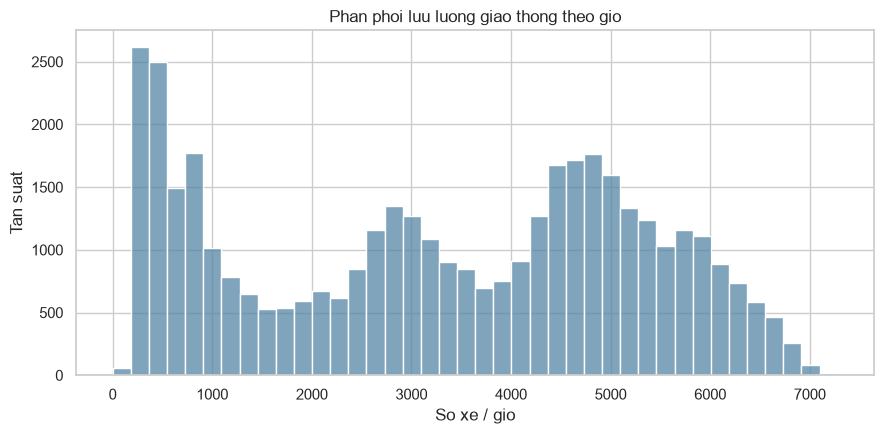

In [10]:
# 1.8. Bieu do phan phoi luu luong giao thong

fig, ax = plt.subplots(figsize=(9,4.5))
sns.histplot(df["traffic_volume"], bins=40, color="#5486a6", ax=ax)
ax.set(title="Phan phoi luu luong giao thong theo gio", xlabel="So xe / gio", ylabel="Tan suat")
plt.tight_layout(); plt.savefig(FIG/"eda_01_traffic_hist.png", dpi=160); plt.show()
# Nhan xet: quan sat hinh dang phan phoi, so dinh va khoang gia tri tap trung;
# luu luong nhieu che do theo gio nen khong gia dinh ngay phan phoi chuan.


### 2.2. Boxplot các biến định lượng

Boxplot giúp quan sát trung vị, khoảng tứ phân vị và các giá trị ngoại lai tiềm năng của lưu lượng giao thông, nhiệt độ và độ che phủ mây.

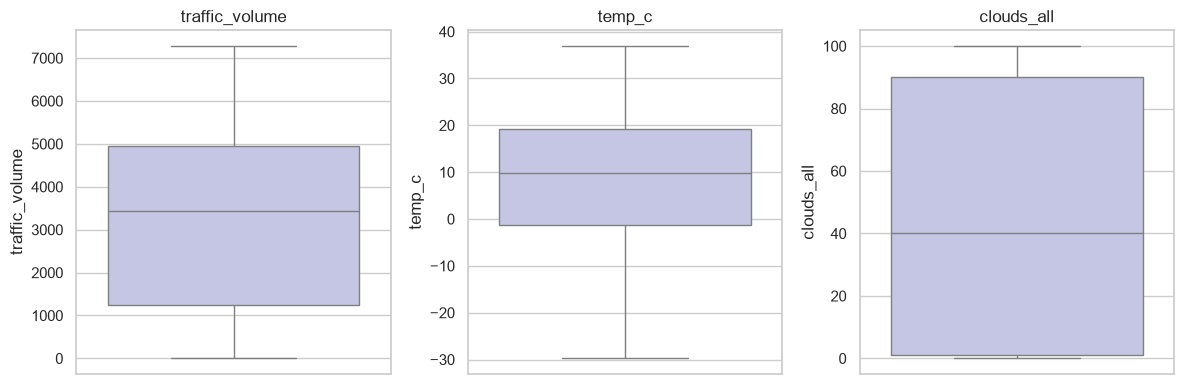

In [11]:
# 1.9. Bieu do hop cua cac bien dinh luong

fig,axes=plt.subplots(1,3,figsize=(12,4))
for ax,col in zip(axes,["traffic_volume","temp_c","clouds_all"]):
    sns.boxplot(y=df[col],ax=ax,color="#bfc2e8")
    ax.set_title(col)
plt.tight_layout();plt.savefig(FIG/"eda_02_boxplots.png",dpi=160);plt.show()
# Diem nam ngoai rau boxplot la quan sat can xem xet, khong phai chac chan la loi.


### 2.3. Lưu lượng giao thông trung bình theo giờ

Biểu đồ đường so sánh lưu lượng giao thông trung bình trong 24 giờ, qua đó xác định thời điểm có lưu lượng cao nhất và thấp nhất.

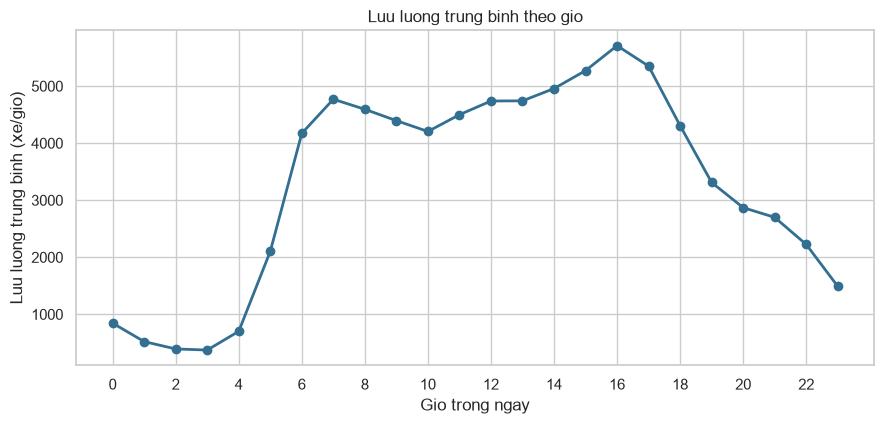

Gio dong nhat: 16h (~5,709 xe/gio).
Gio it xe nhat: 3h (~373 xe/gio).


In [12]:
# 1.10. Luu luong trung binh theo gio

hour_mean=df.groupby("hour")["traffic_volume"].mean()
fig,ax=plt.subplots(figsize=(9,4.4))
ax.plot(hour_mean.index,hour_mean.values,marker="o",linewidth=2,color="#326f91")
ax.set(xticks=range(0,24,2),xlabel="Gio trong ngay",ylabel="Luu luong trung binh (xe/gio)",
       title="Luu luong trung binh theo gio")
plt.tight_layout();plt.savefig(FIG/"eda_03_hourly.png",dpi=160);plt.show()
print(f"Gio dong nhat: {hour_mean.idxmax()}h (~{hour_mean.max():,.0f} xe/gio).")
print(f"Gio it xe nhat: {hour_mean.idxmin()}h (~{hour_mean.min():,.0f} xe/gio).")


### 2.4. Lưu lượng giao thông theo ngày trong tuần

Biểu đồ cột so sánh lưu lượng trung bình từ thứ Hai đến Chủ nhật nhằm quan sát sự khác biệt giữa các ngày trong tuần.

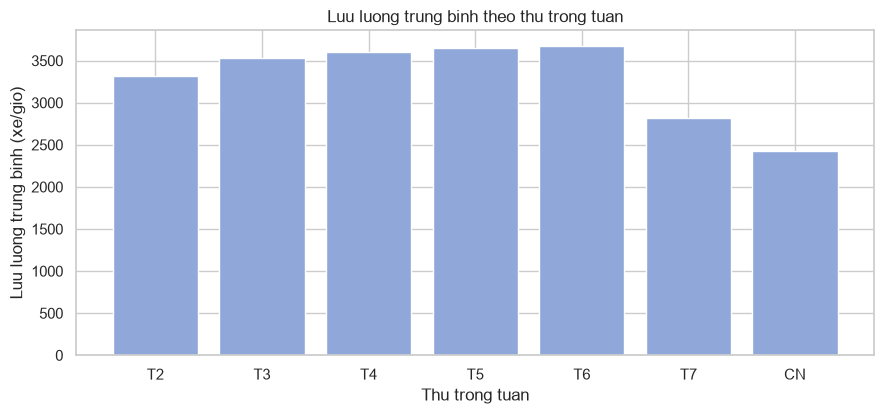

In [13]:
# 1.11. Luu luong trung binh theo ngay trong tuan

day_mean=df.groupby("day_of_week")["traffic_volume"].mean().reindex(range(7))
fig,ax=plt.subplots(figsize=(9,4.3))
ax.bar(["T2","T3","T4","T5","T6","T7","CN"],day_mean.values,color="#8fa7d9")
ax.set(title="Luu luong trung binh theo thu trong tuan",xlabel="Thu trong tuan",ylabel="Luu luong trung binh (xe/gio)")
plt.tight_layout();plt.savefig(FIG/"eda_04_weekdays.png",dpi=160);plt.show()
# Chenh lech mo ta chua chung minh su khac biet co y nghia thong ke.


### 2.5. Mối quan hệ giữa nhiệt độ và lưu lượng giao thông

Biểu đồ phân tán thể hiện mối liên hệ quan sát được giữa nhiệt độ và lưu lượng giao thông trên một mẫu dữ liệu.

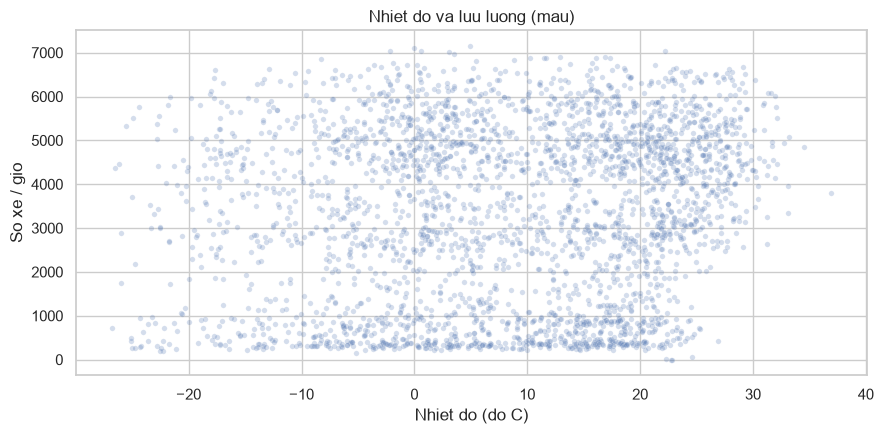

In [14]:
# 1.12. Moi quan he giua nhiet do va luu luong

scatter_df=df[["temp_c","traffic_volume"]].dropna().sample(n=min(3000,df["temp_c"].notna().sum()),random_state=42)
fig,ax=plt.subplots(figsize=(9,4.5))
sns.scatterplot(data=scatter_df,x="temp_c",y="traffic_volume",alpha=.24,s=15,ax=ax)
ax.set(title="Nhiet do va luu luong (mau)",xlabel="Nhiet do (do C)",ylabel="So xe / gio")
plt.tight_layout();plt.savefig(FIG/"eda_05_scatter.png",dpi=160);plt.show()
# Bieu do bieu dien lien he quan sat, khong chung minh nhiet do gay ra thay doi luu luong.


### 2.6. Ma trận tương quan sơ bộ

Ma trận tương quan Pearson giúp quan sát chiều hướng và mức độ liên hệ tuyến tính giữa lưu lượng giao thông với các biến định lượng.

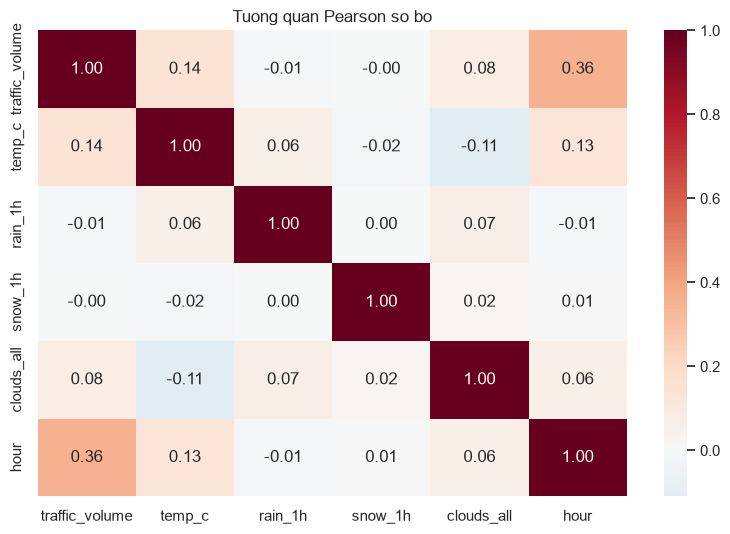

In [15]:
# 1.13. Ma tran tuong quan so bo

corr_vars=["traffic_volume","temp_c","rain_1h","snow_1h","clouds_all","hour"]
corr0=df[corr_vars].corr(method="pearson")
fig,ax=plt.subplots(figsize=(8,5.5))
sns.heatmap(corr0,annot=True,fmt=".2f",cmap="RdBu_r",center=0,ax=ax)
ax.set_title("Tuong quan Pearson so bo")
plt.tight_layout();plt.savefig(FIG/"eda_06_heatmap.png",dpi=160);plt.show()


### 2.7. Phát hiện giá trị ngoại lai bằng IQR

Phương pháp IQR xác định các quan sát nằm ngoài hai cận \(Q1-1.5\times IQR\) và \(Q3+1.5\times IQR\). Những giá trị được đánh dấu cần được xem xét thêm, không mặc nhiên là dữ liệu sai.

In [16]:
# 1.14. Nhan dien gia tri ngoai lai bang IQR
# Ngoai lai theo IQR chi la quan sat can xem xet, khong tu dong la loi.

q1=df[eda_cols].quantile(.25)
q3=df[eda_cols].quantile(.75)
iqr=q3-q1
outlier_count=((df[eda_cols] < (q1-1.5*iqr)) | (df[eda_cols] > (q3+1.5*iqr))).sum()
display(outlier_count.to_frame("So diem ngoai IQR"))
# Phan lon mua/tuyet bang 0 nen IQR=0 co the danh dau tat ca gia tri duong.
# Day la ly do phai xem boi canh, khong xoa may moc cac gia tri ngoai IQR.


,So diem ngoai IQR
traffic_volume,0
temp_c,0
rain_1h,2054
snow_1h,31
clouds_all,0


### 2.8. Phân tích phân phối lượng mưa

Nhóm quan sát phân phối lượng mưa ở toàn bộ dữ liệu và riêng các thời điểm có lượng mưa dương để hiểu rõ đặc điểm của biến này.

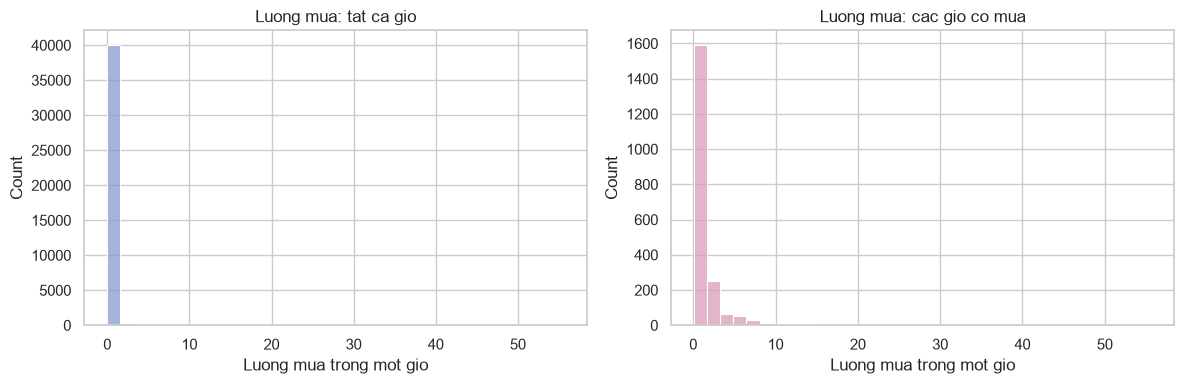

In [17]:
# 1.15. Kiem tra phan phoi luong mua

fig,axes=plt.subplots(1,2,figsize=(12,4))
sns.histplot(df["rain_1h"].dropna(),bins=35,ax=axes[0],color="#879bcf")
axes[0].set(title="Luong mua: tat ca gio",xlabel="Luong mua trong mot gio")
positive_rain=df.loc[df["rain_1h"]>0,"rain_1h"].dropna()
sns.histplot(positive_rain,bins=35,ax=axes[1],color="#d99db9")
axes[1].set(title="Luong mua: cac gio co mua",xlabel="Luong mua trong mot gio")
plt.tight_layout();plt.savefig(FIG/"eda_07_rainfall.png",dpi=160);plt.show()
# Bieu do ben phai chi dai dien cho cac gio co mua, khong phai toan bo thoi gian.


### 2.9. Lưu dữ liệu sau làm sạch

Bộ dữ liệu đã xử lý được lưu thành file CSV để sử dụng thống nhất trong các bước phân tích và xây dựng mô hình tiếp theo.

In [18]:
# 1.16. Luu du lieu da lam sach

df.to_csv(OUT/"cleaned_traffic.csv",index=False,encoding="utf-8-sig")


## III. Phân tích phân phối dữ liệu

### 3.1. Lựa chọn biến nghiên cứu

Nhóm lựa chọn lưu lượng giao thông và nhiệt độ đã chuyển sang độ C để phân tích đặc điểm phân phối của các biến.

In [19]:
# 2.1. Lua chon bien nghien cuu
# Su dung truc tiep df da xu ly o Phan 1, khong tai lai du lieu goc.

traffic=df["traffic_volume"].dropna()
temperature=df["temp_c"].dropna()
print("So quan sat traffic_volume:",len(traffic))
print("So quan sat temp_c:",len(temperature))


So quan sat traffic_volume: 40575
So quan sat temp_c: 40565


### 3.2. Histogram và đường mật độ KDE

Histogram kết hợp KDE giúp quan sát hình dạng phân phối, mức độ tập trung và khả năng lệch của lưu lượng giao thông và nhiệt độ.

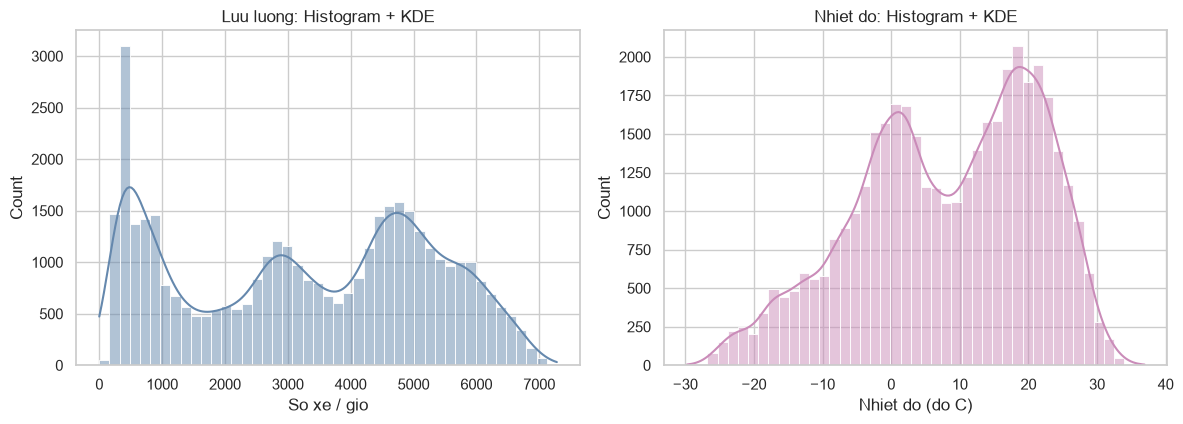

In [20]:
# 2.2. Histogram va duong mat do KDE

fig,axes=plt.subplots(1,2,figsize=(12,4.4))
sns.histplot(traffic,bins=45,kde=True,ax=axes[0],color="#6588ad")
axes[0].set(title="Luu luong: Histogram + KDE",xlabel="So xe / gio")
sns.histplot(temperature,bins=45,kde=True,ax=axes[1],color="#ca8cb9")
axes[1].set(title="Nhiet do: Histogram + KDE",xlabel="Nhiet do (do C)")
plt.tight_layout();plt.savefig(FIG/"phan_phoi_01_hist_kde.png",dpi=160);plt.show()


### 3.3. Biểu đồ Q-Q

Biểu đồ Q-Q so sánh các phân vị của dữ liệu với phân vị lý thuyết của phân phối chuẩn để đánh giá sơ bộ mức độ phù hợp với phân phối chuẩn.

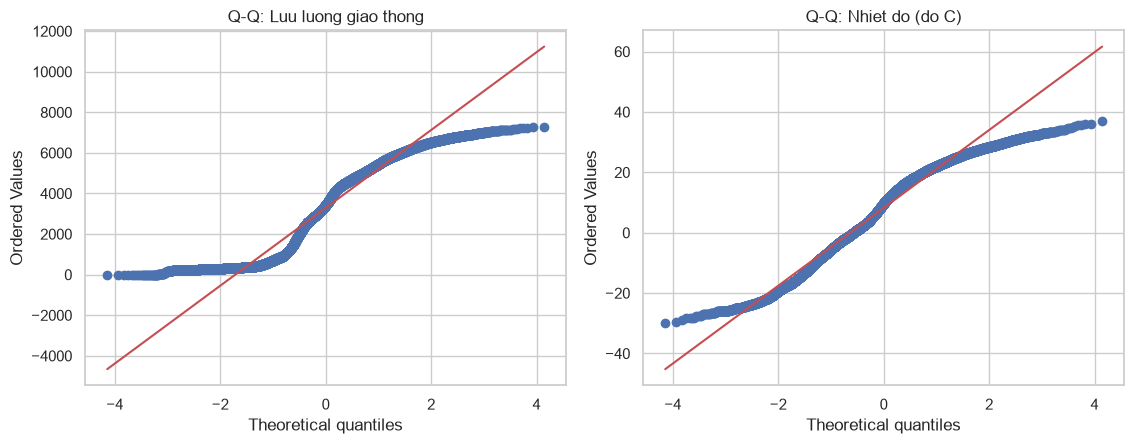

In [21]:
# 2.3. Q-Q plot so voi phan phoi chuan

fig,axes=plt.subplots(1,2,figsize=(11.5,4.6))
stats.probplot(traffic,dist="norm",plot=axes[0]); axes[0].set_title("Q-Q: Luu luong giao thong")
stats.probplot(temperature,dist="norm",plot=axes[1]); axes[1].set_title("Q-Q: Nhiet do (do C)")
plt.tight_layout();plt.savefig(FIG/"phan_phoi_02_qq.png",dpi=160);plt.show()
# Diem lech co he thong khoi duong thang cho thay phan phoi khac chuan.


### 3.4. Kiểm định Shapiro–Wilk

Kiểm định Shapiro–Wilk được sử dụng để đánh giá giả thuyết dữ liệu có phân phối chuẩn ở mức ý nghĩa 0,05.

In [22]:
# H0: Bien co phan phoi chuan. H1: Bien khong co phan phoi chuan.
# Lay ngau nhien toi da 5000 quan sat, muc y nghia 0.05.

normality_results=[]
for label,series in [("traffic_volume",traffic),("temp_c",temperature)]:
    sample=series.sample(n=min(5000,len(series)),random_state=42)
    w,p=stats.shapiro(sample)
    normality_results.append({"variable":label,"sample_n":len(sample),"Shapiro_W":w,"p_value":p,
                              "conclusion":"Bac bo H0 (khong chuan)" if p<.05 else "Chua bac bo H0"})
normality_df=pd.DataFrame(normality_results)
display(normality_df)
normality_df.to_csv(OUT_01/"shapiro_results.csv",index=False,encoding="utf-8-sig")


,variable,sample_n,Shapiro_W,p_value,conclusion
0,traffic_volume,5000,0.933156,1.129221e-42,Bac bo H0 (khong chuan)
1,temp_c,5000,0.968733,1.171547e-31,Bac bo H0 (khong chuan)


### 3.5. Kiểm tra mức độ phù hợp với phân phối Poisson

Nhóm so sánh phương sai với trung bình của lưu lượng giao thông để đánh giá sơ bộ mức độ phù hợp với đặc điểm của phân phối Poisson.

In [23]:
# 2.5. Kiem tra tinh phu hop cua phan phoi Poisson
# Voi Poisson don gian: ky vong bang phuong sai (lambda).
# Ty so phuong sai / trung binh duoc dung de danh gia so bo.

poisson_mean = traffic.mean()
poisson_var = traffic.var(ddof=1)
dispersion = poisson_var / poisson_mean

print(f"Trung binh: {poisson_mean:,.3f}")
print(f"Phuong sai mau: {poisson_var:,.3f}")
print(f"Ty so phuong sai / trung binh: {dispersion:,.2f}")

# Danh gia so bo: ty so rat lon hon 1 cho thay hien tuong qua phan tan.
poisson_conclusion = (
    "Du lieu qua phan tan so voi Poisson don gian"
    if dispersion > 1.5 else "Can tiep tuc kiem tra do phu hop cua Poisson"
)
print("Ket qua xem xet Poisson:", poisson_conclusion)

# Luu y: day la kiem tra so bo; so xe thay doi theo gio va ngay trong tuan.


Trung binh: 3,290.650
Phuong sai mau: 3,939,323.501
Ty so phuong sai / trung binh: 1,197.13
Ket qua xem xet Poisson: Du lieu qua phan tan so voi Poisson don gian


### 3.6. Tổng hợp kết quả phân tích phân phối

Nhóm tổng hợp kết quả kiểm định chuẩn và tỷ số phương sai trên trung bình để nhận xét đặc điểm phân phối của dữ liệu.

In [24]:
# 2.6. Tong hop ket qua phan tich phan phoi

for r in normality_results:
    print(f"{r['variable']}: W={r['Shapiro_W']:.4f}; p={r['p_value']:.3g}; {r['conclusion']}.")
print(f"Poisson don gian: variance/mean = {dispersion:,.1f}.")
# Ve mat thuc te, luu luong theo gio co cau truc theo gio va ngay;
# nhiet do con bien doi theo mua. Khong nen khang dinh nguyen nhan chi tu phan phoi.


traffic_volume: W=0.9332; p=1.13e-42; Bac bo H0 (khong chuan).
temp_c: W=0.9687; p=1.17e-31; Bac bo H0 (khong chuan).
Poisson don gian: variance/mean = 1,197.1.
